In [ ]:
# ==============================================================================
# ENVIRONMENT SETUP & DEPENDENCIES
# ==============================================================================

# Install dependencies if running in a cloud notebook (e.g., Google Colab).
# !pip install -q language-tool-python sentence-transformers jiwer openpyxl

import pandas as pd
import numpy as np
from scipy import stats
import warnings

# Suppress non-critical execution warnings for a clean public artifact
warnings.filterwarnings('ignore')

In [ ]:
# ==============================================================================
# CORPUS INGESTION & TOPIC CONSOLIDATION
# ==============================================================================

# NOTE FOR REVIEWERS: Set `base_path` to the repository root directory.
base_path = '..'
df = pd.read_csv(f'{base_path}/data/bssd_anonymized_corpus.csv')

# Reposition institutional identifier for tabular clarity
col = df.pop('school_id')
df.insert(3, col.name, col)

print(f"Initial Corpus Size: {df.shape[0]} essays")
print(f"Initial Unique Prompts: {len(df['prompt_name'].unique())}\n")

# 1. Prune statistically underrepresented prompts
prompts_to_remove = ["Childhood Memories", "Your Favourite Hobby"]
df = df[~df['prompt_name'].isin(prompts_to_remove)]

# 2. Consolidate semantically identical prompts to establish the N=5 curriculum topics
df['prompt_name'] = df['prompt_name'].replace('The Game You Like the Most', 'Your Favourite Game')

print("Final Topic Distribution (Post-Consolidation):")
display(df['prompt_name'].value_counts())

Initial Corpus Size: 312 essays
Initial Unique Prompts: 8

Final Topic Distribution (Post-Consolidation):


prompt_name
The Importance of Reading Newspaper    120
The Season You Like the Most            66
Your Favourite Game                     62
Your Favourite Poet                     32
Students and Social Service             28
Name: count, dtype: int64

In [3]:
# ==============================================================================
# BASE TARGET NORMALIZATION
# ==============================================================================
print(f"Detected holistic grading scales within corpus: {df['scale_max'].unique()}")

# Normalize raw human evaluations to a preliminary 0.0 - 1.0 continuous scale
df['normalized_score'] = df['raw_score'] / df['scale_max']

print("\nSample of Normalized Ground Truth Targets:")
# Using a fixed random state purely for a clean, reproducible display output
display(df[['essay_id', 'prompt_name', 'school_id', 'raw_score', 'scale_max', 'normalized_score']].sample(5, random_state=42))

Detected holistic grading scales within corpus: [20 12]

Sample of Normalized Ground Truth Targets:


,essay_id,prompt_name,school_id,raw_score,scale_max,normalized_score
292,essay293,Students and Social Service,School 1,10,20,0.500000
9,essay10,The Importance of Reading Newspaper,School 1,18,20,0.900000
57,essay58,Your Favourite Poet,School 1,5,12,0.416667
60,essay61,Your Favourite Poet,School 1,4,12,0.333333
25,essay26,The Importance of Reading Newspaper,School 1,10,20,0.500000


In [4]:
df.head()

,essay_id,prompt_name,essay_text,school_id,raw_score,scale_max,normalized_score
0,essay01,The Importance of Reading Newspaper,Newspaper is the paper which gives us news and...,School 1,18,20,0.9
1,essay02,The Importance of Reading Newspaper,Reading Newspaper is a valuable habit in one's...,School 1,18,20,0.9
2,essay03,The Importance of Reading Newspaper,Newspaper is the mirror of the world. Newspape...,School 1,16,20,0.8
3,essay04,The Importance of Reading Newspaper,Reading newspaper plays an important role in k...,School 1,18,20,0.9
4,essay05,The Importance of Reading Newspaper,Newspaper is one of the most important thing i...,School 1,18,20,0.9


In [5]:
# ==============================================================================
# STATISTICAL AUDIT OF INTER-RATER RELIABILITY (ANOVA)
# ==============================================================================
# Group normalized scores by institutional origin to test for rater strictness
school_groups = [group["normalized_score"].values for name, group in df.groupby("school_id")]

f_statistic, p_value = stats.f_oneway(*school_groups)

print("==================================================")
print("ONE-WAY ANOVA: GRADING VARIANCE ACROSS INSTITUTIONS")
print("==================================================")
print(f"F-Statistic : {f_statistic:.4f}")
print(f"P-Value     : {p_value:.4e}\n")

# Objective interpretation of the P-Value
if p_value < 0.05:
    print("[WARNING] Null hypothesis rejected: Statistically significant grading bias detected.")
    print("[ACTION] Intra-School Z-Score Standardization required to mitigate rater strictness.")
else:
    print("[PASS] Null hypothesis accepted: No significant grading bias detected.")

ONE-WAY ANOVA: GRADING VARIANCE ACROSS INSTITUTIONS
F-Statistic : 36.6577
P-Value     : 3.0027e-20

[WARNING] Null hypothesis rejected: Statistically significant grading bias detected.
[ACTION] Intra-School Z-Score Standardization required to mitigate rater strictness.


In [6]:
# ==============================================================================
# BIAS MITIGATION & TARGET VARIABLE SCALING
# ==============================================================================
print("Applying Intra-School Z-Score Standardization...")
# Standardize scores within each school to neutralize teacher strictness/leniency
df['z_score'] = df.groupby('school_id')['normalized_score'].transform(
    lambda x: (x - x.mean()) / x.std() if x.std() > 0 else 0
)

print("Applying Global Min-Max Scaling...")
# Compress the unbounded Z-scores into a strict [0.0, 1.0] range for neural stability
z_min = df['z_score'].min()
z_max = df['z_score'].max()
df['final_target_score'] = (df['z_score'] - z_min) / (z_max - z_min)

print("\nValidation: Z-Score Mean and Standard Deviation per School")
display(df.groupby('school_id')['z_score'].agg(['mean', 'std']).round(4))

Applying Intra-School Z-Score Standardization...
Applying Global Min-Max Scaling...

Validation: Z-Score Mean and Standard Deviation per School


,mean,std
school_id,,
School 1,0.0,1.0
School 2,0.0,1.0
School 3,-0.0,1.0
School 4,0.0,1.0


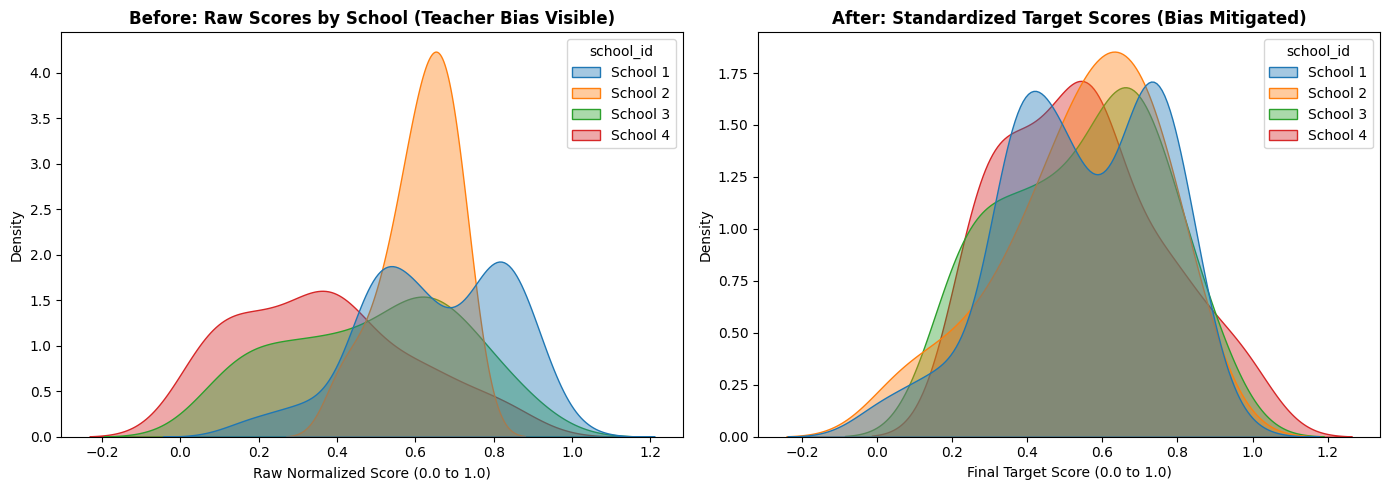

In [7]:
# ==============================================================================
# VISUALIZATION OF BIAS MITIGATION
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 5))

# Panel A: Raw Scores showing institutional bias
plt.subplot(1, 2, 1)
sns.kdeplot(data=df, x="normalized_score", hue="school_id", fill=True, common_norm=False, alpha=0.4)
plt.title("Before: Raw Scores by School (Teacher Bias Visible)", fontweight='bold')
plt.xlabel("Raw Normalized Score (0.0 to 1.0)")
plt.ylabel("Density")

# Panel B: Standardized targets proving bias removal
plt.subplot(1, 2, 2)
sns.kdeplot(data=df, x="final_target_score", hue="school_id", fill=True, common_norm=False, alpha=0.4)
plt.title("After: Standardized Target Scores (Bias Mitigated)", fontweight='bold')
plt.xlabel("Final Target Score (0.0 to 1.0)")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

In [8]:
# ==============================================================================
# LINGUISTIC & SEMANTIC FEATURE EXTRACTION
# ==============================================================================
import re
import language_tool_python
from sentence_transformers import SentenceTransformer, util
from tqdm.auto import tqdm
tqdm.pandas()

print("Initializing parsing models...")
tool = language_tool_python.LanguageTool('en-US', language_tool_download_version='6.4')
similarity_model = SentenceTransformer('all-MiniLM-L6-v2')

# --- 1. Helper Functions ---
def clean_text(text):
    if not isinstance(text, str): return ""
    return re.sub(r'\s+', ' ', re.sub(r'[^\x00-\x7F]+', ' ', text)).strip()

def calculate_ttr(text):
    words = re.findall(r'\b\w+\b', text.lower())
    return len(set(words)) / len(words) if words else 0

def extract_errors(text):
    if not isinstance(text, str) or text.strip() == "":
        return 0, 0
    matches = tool.check(text)
    casing_errors = sum(1 for m in matches if 'CASING' in getattr(m, 'ruleId', '').upper() or 'UPPERCASE' in getattr(m, 'ruleId', '').upper() or 'CASING' in getattr(m, 'category', '').upper())
    mechanical_errors = len(matches) - casing_errors
    return mechanical_errors, casing_errors

# --- 2. Execution Pipeline ---
print("Executing text sanitization protocol...")
df['clean_essay_text'] = df['essay_text'].apply(clean_text)

print("Extracting token volume (N)...")
df['trait_5_word_count'] = df['clean_essay_text'].apply(lambda x: len(re.findall(r'\b\w+\b', x)))

print("Extracting syntactic violations (Grammar & Casing)...")
df['mech_errors'], df['case_errors'] = zip(*df['clean_essay_text'].progress_apply(extract_errors))

print("Calculating morphological densities...")
df['trait_1_mechanical_density'] = np.where(df['trait_5_word_count'] > 0, df['mech_errors'] / df['trait_5_word_count'], 0)
df['trait_2_casing_density'] = np.where(df['trait_5_word_count'] > 0, df['case_errors'] / df['trait_5_word_count'], 0)

print("Calculating lexical diversity (TTR)...")
df['trait_3_lexical_richness'] = df['clean_essay_text'].apply(calculate_ttr)

print("Computing semantic prompt relevance (Cosine Similarity)...")
prompt_embeddings = similarity_model.encode(df['prompt_name'].tolist())
essay_embeddings = similarity_model.encode(df['clean_essay_text'].tolist())
df['trait_4_prompt_relevance'] = [util.cos_sim(p, e).item() for p, e in zip(prompt_embeddings, essay_embeddings)]

# Clean temporary calculation arrays
df = df.drop(columns=['mech_errors', 'case_errors'], errors='ignore')
print("Feature Engineering Complete.")

Initializing parsing models...


Unzipping C:\Users\DCL\AppData\Local\Temp\tmpq7ytvris.zip to C:\Users\DCL\.cache\language_tool_python.
Downloaded https://www.languagetool.org/download/LanguageTool-6.4.zip to C:\Users\DCL\.cache\language_tool_python.
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


Executing text sanitization protocol...
Extracting token volume (N)...
Extracting syntactic violations (Grammar & Casing)...


100%|██████████| 308/308 [3:48:19<00:00, 44.48s/it]      


Calculating morphological densities...
Calculating lexical diversity (TTR)...
Computing semantic prompt relevance (Cosine Similarity)...
Feature Engineering Complete.


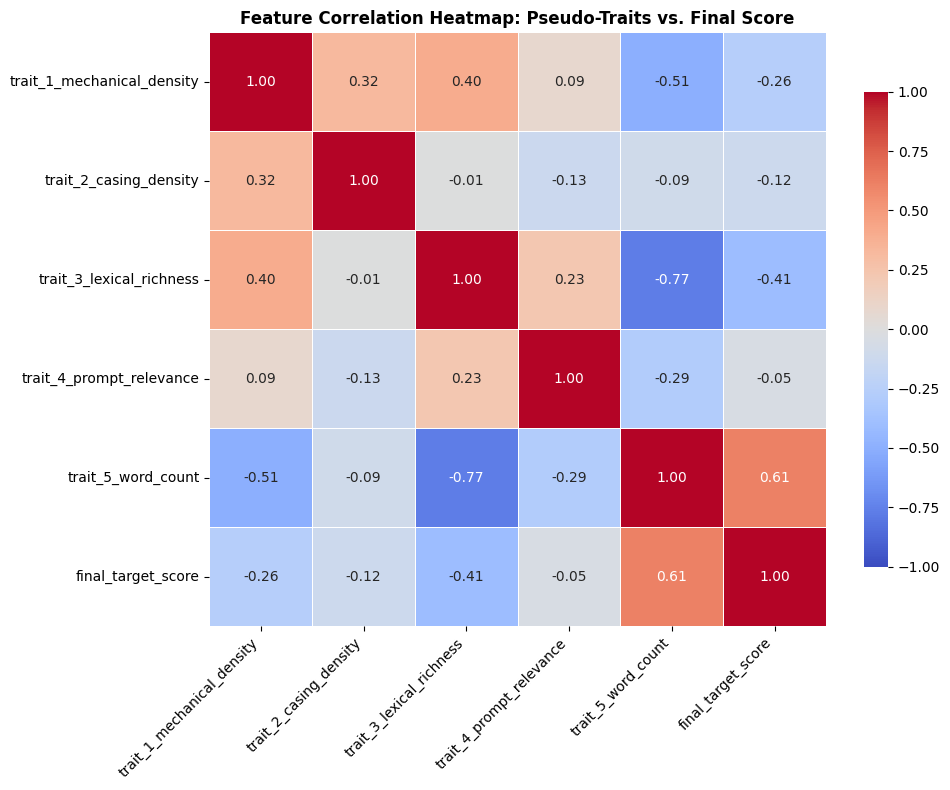

Preprocessed corpus successfully archived to: ../data/final_preprocessed_data.csv


In [9]:
# ==============================================================================
# FEATURE COLLINEARITY AUDIT & EXPORT
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

feature_cols = [
    'trait_1_mechanical_density',
    'trait_2_casing_density',
    'trait_3_lexical_richness',
    'trait_4_prompt_relevance',
    'trait_5_word_count',
    'final_target_score'
]

# Calculate Spearman correlation (optimized for non-linear pedagogical assessments)
corr_matrix = df[feature_cols].corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f",
            linewidths=.5, cbar_kws={"shrink": .8})

plt.title("Feature Correlation Heatmap: Pseudo-Traits vs. Final Score", fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Export Final Artifact
export_path = f'{base_path}/data/final_preprocessed_data.csv'
df.to_csv(export_path, index=False)
print(f"Preprocessed corpus successfully archived to: {export_path}")

In [10]:
# ==============================================================================
# CREDIBILITY AUDIT A (OCR DEGRADATION & HITL CORRECTION)
# ==============================================================================
import jiwer
import difflib

print("Loading Verified OCR Workflow Logs...")
audit_path_a = f'{base_path}/data/ocr_audit_logs.csv'
audit_df = pd.read_csv(audit_path_a)

audit_df['initial_ocr'] = audit_df['initial_ocr'].astype(str)
audit_df['hitl_corrected'] = audit_df['hitl_corrected'].astype(str)

print(f"Loaded {len(audit_df)} workflow logs. Calculating Token-Level Edit Distances (WER)...")

total_original_tokens = 0
total_edits = 0
wers = []

for orig, hitl in zip(audit_df['initial_ocr'], audit_df['hitl_corrected']):
    out = jiwer.process_words(hitl, orig)
    total_original_tokens += len(orig.split())
    total_edits += (out.insertions + out.deletions + out.substitutions)
    wers.append(out.wer)

correction_percentage = (total_edits / total_original_tokens) * 100 if total_original_tokens > 0 else 0.0
mean_wer = np.mean(wers)

print("\n==================================================")
print("OCR DEGRADATION & HITL CORRECTION AUDIT RESULTS")
print("==================================================")
print(f"Total Essays Audited:      {len(audit_df)}")
print(f"Total Tokens Evaluated:    {total_original_tokens:,}")
print(f"Total Tokens Corrected:    {total_edits:,}")
print(f"Token Correction Rate:     {correction_percentage:.2f}%")
print(f"Mean Word Error Rate:      {mean_wer:.4f}")
print("==================================================")

Loading Verified OCR Workflow Logs...
Loaded 301 workflow logs. Calculating Token-Level Edit Distances (WER)...

OCR DEGRADATION & HITL CORRECTION AUDIT RESULTS
Total Essays Audited:      301
Total Tokens Evaluated:    103,572
Total Tokens Corrected:    2,679
Token Correction Rate:     2.59%
Mean Word Error Rate:      0.0278


In [11]:
# ==============================================================================
# CREDIBILITY AUDIT B (DOUBLE-TRANSCRIPTION IAA)
# ==============================================================================
print("Loading 30-Essay Double-Transcription Audit Dataset...")
audit_path_b = f'{base_path}/data/audit_30_sample_selection.xlsx'
iaa_df = pd.read_excel(audit_path_b)

iaa_df['essay_text'] = iaa_df['essay_text'].astype(str)
iaa_df['typed_essay_text'] = iaa_df['typed_essay_text'].astype(str)

print(f"Loaded {len(iaa_df)} double-transcribed logs. Computing Inter-Annotator Agreement...")

total_reference_tokens = 0
total_disagreements = 0
iaa_wers = []

for dataset_text, typed_text in zip(iaa_df['essay_text'], iaa_df['typed_essay_text']):
    # 'typed_essay_text' acts as reference ground truth
    out = jiwer.process_words(typed_text, dataset_text)
    total_reference_tokens += len(typed_text.split())
    total_disagreements += (out.insertions + out.deletions + out.substitutions)
    iaa_wers.append(out.wer)

disagreement_percentage = (total_disagreements / total_reference_tokens) * 100 if total_reference_tokens > 0 else 0.0
mean_iaa_wer = np.mean(iaa_wers)

print("\n==================================================")
print("DOUBLE-TRANSCRIPTION (IAA) AUDIT RESULTS")
print("==================================================")
print(f"Total Essays Audited:            {len(iaa_df)}")
print(f"Total Reference Tokens:          {total_reference_tokens:,}")
print(f"Total Tokens Disagreed:          {total_disagreements:,}")
print(f"Inter-Annotator Disagreement:    {disagreement_percentage:.2f}%")
print(f"Mean Word Error Rate:            {mean_iaa_wer:.4f}")
print("==================================================")

Loading 30-Essay Double-Transcription Audit Dataset...
Loaded 30 double-transcribed logs. Computing Inter-Annotator Agreement...

DOUBLE-TRANSCRIPTION (IAA) AUDIT RESULTS
Total Essays Audited:            30
Total Reference Tokens:          9,749
Total Tokens Disagreed:          219
Inter-Annotator Disagreement:    2.25%
Mean Word Error Rate:            0.0302
